# Topological analysis

## Import

In [1]:
import numpy as np
import seaborn as sns
import os 
import sys
import pandas as pd

from scipy.signal import savgol_filter

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import ticker, cm

sys.path.append('scripts') #dirty way to import our script
from scripts.calcFES import calcFES, calcDeltaF, calcESS
from mlcolvar.utils.fes import compute_fes
from mlcolvar.utils.io import load_dataframe

In [2]:
#plot-related stuff
import matplotlib.pyplot as plt
from IPython.display import clear_output

#set bigger font sizes
SMALL_SIZE = 8
MEDIUM_SIZE = 8
BIG_SIZE = 8
plt.rc('font', size=SMALL_SIZE)        # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)   # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)  # legend fontsize
plt.rc('figure', titlesize=BIG_SIZE)   # fontsize of the figure title

try:
# https://github.com/luigibonati/fessa-color-palette/blob/master/fessa.py
    import fessa
    plt.set_cmap('fessa')
except:
    pass # no big deal

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,

    # Axes
    "axes.titlesize": 8,
    "axes.labelsize": 8,

    # Tick labels
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Legend
    "legend.fontsize": 8,

    # Figure title
    "figure.titlesize": 8,

    # Colorbar (uses axes settings, but these help in some cases)
    "axes.titlepad": 6,
})

In [3]:
#useful constants for our simulations
KB = 0.0083144621
T = 300
BETA0 = 1/(KB*T)
KBT = KB*T

cm2inch = 1/2.54

# Conventional MD analysis

## Read data

In [4]:
df = pd.read_csv('Conventional_MD.csv') 
df = df.rename(columns={"C": "X"})
df['Time (us)'] = 10 * df.index / 10000
df.head()

,Unnamed: 0,protid,P,S,X,I,T,L,Time (us)
0,0,chainB_00001_,20,7,1,0.714,0.250,0.036,0.000
1,1,chainB_00002_,0,0,0,NaN,NaN,NaN,0.001
2,2,chainB_00003_,0,0,0,NaN,NaN,NaN,0.002
3,3,chainB_00004_,10,5,0,0.667,0.333,0.000,0.003
4,4,chainB_00005_,11,10,0,0.524,0.476,0.000,0.004


## Plot topological parameters dynamics

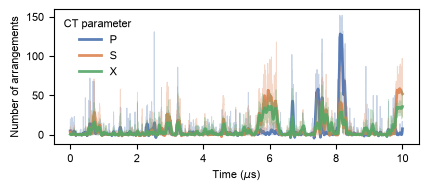

In [6]:
# =============================================================================
# Parameters
# =============================================================================

window_length = 101   # Must be odd
polyorder = 3

# =============================================================================
# Plot
# =============================================================================

plt.figure(figsize=(11 * cm2inch, 5 * cm2inch))

palette = sns.color_palette("deep", 3)
columns = ["P", "S", "X"]

for color, col in zip(palette, columns):

    # Raw data
    plt.plot(
        df["Time (us)"],
        df[col],
        color=color,
        alpha=0.3,
        lw=0.7,
    )

    # Savitzky-Golay filtered data
    y_smooth = savgol_filter(
        df[col],
        window_length=window_length,
        polyorder=polyorder
    )

    plt.plot(
        df["Time (us)"],
        y_smooth,
        color=color,
        alpha=0.9,
        lw=2,
        label=col
    )

plt.xlabel(r"Time ($\mu$s)")
plt.ylabel("Number of arrangements")

plt.legend(title="CT parameter", frameon=False, loc = 'upper left')

plt.tight_layout()

plt.savefig(
    "images/CT_timetrace.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

## Plot P,X FES

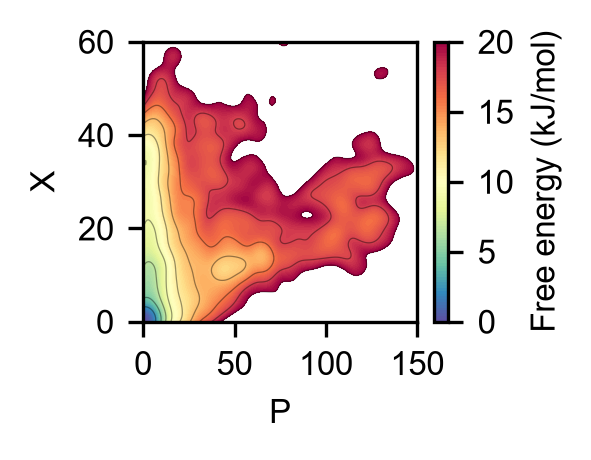

In [91]:
var1 = "P"
var2 = "X"
data = df

fig, ax = plt.subplots(
    1, 1,
    figsize=(5*cm2inch, 4*cm2inch),
    dpi=300,
)

cv1 = data[var1].to_numpy(dtype=float)
cv2 = data[var2].to_numpy(dtype=float)

cv = np.vstack([cv1, cv2])

fes, grid, bounds, error = compute_fes(
    cv.T,
    weights=None,
    blocks=1,
    kbt=KB * T,
    bandwidth=0.03,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
    backend="KDEpy",
)

extent = [item for sublist in bounds for item in sublist]

# Filled contour
pp = ax.contourf(
    fes,
    extent=extent,
    levels=np.linspace(0, 20, 101),
    cmap="Spectral_r",
    # extend="max"
)

# Contour lines
ax.contour(
    fes,
    extent=extent,
    levels=np.linspace(0, 20, 10),
    colors="black",
    linewidths=0.3,
    alpha=0.4,
)

# ------------------------------------------------------------------
# Axis
# ------------------------------------------------------------------

ax.set_xlabel(var1)
ax.set_ylabel(var2)
ax.set_xlim(0,150)
ax.set_ylim(0,60)
ax.set_xticks(np.arange(0, 151, 50))
ax.set_yticks(np.arange(0, 61, 20))

# ------------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------------

cbar = fig.colorbar(
    pp,
    ax=ax,
)

cbar.set_label(r"Free energy (kJ/mol)")

# Optional: nicer ticks
cbar.set_ticks(np.arange(0, 21, 5))

plt.savefig(
    f"images/CT_FES_{var1}_{var2}.png",
    dpi=600,
    bbox_inches="tight",
)

plt.tight_layout()
plt.show()

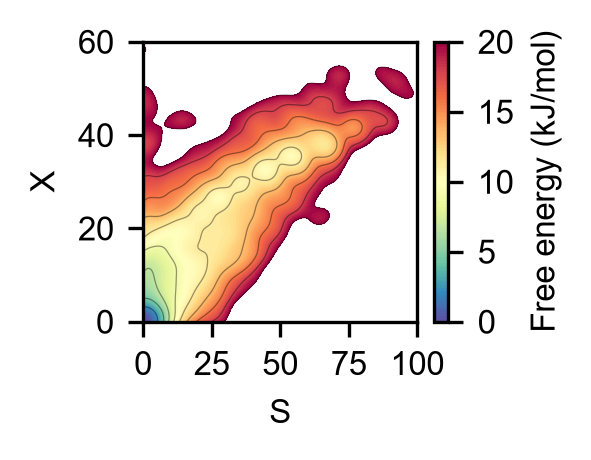

In [92]:
var1 = "S"
var2 = "X"
data = df

fig, ax = plt.subplots(
    1, 1,
    figsize=(5*cm2inch, 4*cm2inch),
    dpi=300,
)

cv1 = data[var1].to_numpy(dtype=float)
cv2 = data[var2].to_numpy(dtype=float)

cv = np.vstack([cv1, cv2])

fes, grid, bounds, error = compute_fes(
    cv.T,
    weights=None,
    blocks=1,
    kbt=KB * T,
    bandwidth=0.03,
    scale_by="range",
    plot=False,
    plot_max_fes=100,
    eps=1e-10,
    backend="KDEpy",
)

extent = [item for sublist in bounds for item in sublist]

# Filled contour
pp = ax.contourf(
    fes,
    extent=extent,
    levels=np.linspace(0, 20, 101),
    cmap="Spectral_r",
    # extend="max"
)

# Contour lines
ax.contour(
    fes,
    extent=extent,
    levels=np.linspace(0, 20, 10),
    colors="black",
    linewidths=0.3,
    alpha=0.4,
)

# ------------------------------------------------------------------
# Axis
# ------------------------------------------------------------------

ax.set_xlabel(var1)
ax.set_ylabel(var2)
ax.set_xlim(0,100)
ax.set_ylim(0,60)
ax.set_xticks(np.arange(0, 101, 25))
ax.set_yticks(np.arange(0, 61, 20))

# ------------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------------

cbar = fig.colorbar(
    pp,
    ax=ax,
)

cbar.set_label(r"Free energy (kJ/mol)")

# Optional: nicer ticks
cbar.set_ticks(np.arange(0, 21, 5))

plt.savefig(
    f"images/CT_FES_{var1}_{var2}.png",
    dpi=600,
    bbox_inches="tight",
)

plt.tight_layout()
plt.show()

## Topology matrix analysis

In [7]:
from collections import defaultdict

In [8]:
path = r'C:\Users\vacaa\Documents\REPORTS\170\Code\CT_matrix'

files = os.listdir(path)
files.sort()
files = [os.path.join(path, fl) for fl in files]


# Dictionary:
# topology_counts[(contact1, contact2)][type] = number of occurrences

topology_counts = defaultdict(lambda: defaultdict(int))


for filename in files[:]:

    df = pd.read_csv(
        filename,
        sep=";",
        index_col=0
    )

    contacts = df.index.tolist()

    # loop over upper triangle only
    for i in range(len(contacts)):
        for j in range(i+1, len(contacts)):

            c1 = contacts[i]
            c2 = contacts[j]

            topology = df.iloc[i,j]

            if topology != "-":
                topology_counts[(c1,c2)][topology] += 1


In [9]:
rows = []
for (c1, c2), counts in topology_counts.items():

    for topology, count in counts.items():

        rows.append({
            "Contact_1": c1,
            "Contact_2": c2,
            "Topology": topology,
            "Count": count,
            "Probability": count / 10000
        })

topology_df = pd.DataFrame(rows)

# Aggregate topology counts per Contact_1
topology_contact_counts = (
    topology_df
    .groupby(["Contact_1", "Topology"])["Count"]
    .sum()
    .reset_index()
)

# Extract residue numbers without regex
residues = (
    topology_contact_counts["Contact_1"]
    .str.strip("[]")
    .str.split("-")
)

topology_contact_counts["Res_1"] = residues.str[0].astype(int)
topology_contact_counts["Res_2"] = residues.str[1].astype(int)
# topology_contact_counts['Count']/=10000

topology_contact_counts.head()

,Contact_1,Topology,Count,Res_1,Res_2
0,[0 - 10],C,41,0,10
1,[0 - 10],CP,44,0,10
2,[0 - 10],CP-1,237,0,10
3,[0 - 10],CS,16,0,10
4,[0 - 10],P-1,852,0,10


In [10]:
topology_contact_counts.Topology.unique()

<StringArray>
['C', 'CP', 'CP-1', 'CS', 'P-1', 'S']
Length: 6, dtype: str

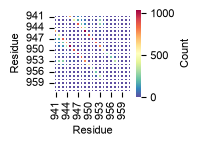

In [23]:
# Select topology to plot
topology_type = "CS"

# Keep only one topology
topology_contact_counts_type = (
    topology_contact_counts[
        topology_contact_counts["Topology"] == topology_type
    ].copy()
)

# Number of residues (0...21)
n_res = 21

# All residue pairs
all_pairs = pd.MultiIndex.from_product(
    [range(n_res), range(n_res)],
    names=["Res_1", "Res_2"]
)

# Add missing residue pairs with Count = 0
topology_contact_counts_type = (
    topology_contact_counts_type
    .set_index(["Res_1", "Res_2"])
    .reindex(all_pairs)
    .fillna({"Count": 0})
    .reset_index()
)
topology_contact_counts_type['Res_1'] = topology_contact_counts_type['Res_1'] + 941
topology_contact_counts_type['Res_2'] = topology_contact_counts_type['Res_2'] + 941

# Create matrix
contact_map = (
    topology_contact_counts_type
    .pivot(
        index="Res_1",
        columns="Res_2",
        values="Count"
    )
)
contact_map += contact_map.T

# Plot
plt.figure(figsize=(5 * cm2inch, 4 * cm2inch))

sns.heatmap(
    contact_map,
    cmap="Spectral_r",
    square=True,
    linewidths=0.3,
    cbar_kws={"label": "Count"}
)

plt.xlabel("Residue")
plt.ylabel("Residue")
# plt.title(f"{topology_type} topology occurrence")

plt.tight_layout()

plt.savefig(
    f"images/CT_residuematrix_{topology_type}.png",
    dpi=600,
    # bbox_inches="tight",
)

plt.show()

# OneOPES MD analysis


In [21]:
# OneOPES MD
colvar_list = []
path_folding = r'C:/Users/vacaa/Documents/REPORTS/170/data/Folding_and_binding/OneOPES'

for i,j in enumerate([1,2,3,4]):
    
    colvar = load_dataframe(f'{path_folding}/{j}/0/COLVAR.0')[::50]
    
    colvar['Replica'] = 0*len(colvar)
    colvar['Repeat'] = [j]*len(colvar)
    colvar.reset_index(drop=True, inplace=True)


    topology = pd.read_csv(f'{path_folding}/{j}/0/pscresults_{j}.csv') 
    topology = topology.rename(columns={"C": "X"})
    topology.reset_index(drop=True, inplace=True)

    colvar = pd.concat([colvar, topology], axis=1)

    colvar_list.append(colvar)

    

colvar = pd.concat(colvar_list)
colvar['radius'] = np.sqrt(colvar['poa_d.proj']**2 + colvar['poa_d.ext']**2)
colvar.replace(np.nan, 0, inplace=True)
colvar['bias_sum'] = np.sum(colvar[['opes1.bias']].to_numpy(), axis = 1)
colvar['time']/=1000

In [27]:
colvar

,time,opes1.bias,opes1.rct,opes1.zed,opes1.neff,opes1.nker,ene,alpha,cmap_hel_sum,cmap_N_sum,...,Unnamed: 0,protid,P,S,X,I,T,L,radius,bias_sum
0,0.0,-40.000000,-40.000000,1.000000,1.000000,0.0,-735368.0000,13.583850,0.871651,0.818788,...,0,1onv_pbc_prot_ions_0001_B,0,55,36,0.000,0.604,0.396,1.793975,-40.000000
1,0.1,-40.000000,-40.000000,1.000000,1.000000,0.0,-775699.6875,13.113782,0.841812,0.809756,...,1,1onv_pbc_prot_ions_0002_B,0,55,36,0.000,0.604,0.396,1.830823,-40.000000
2,0.2,-40.000000,-40.000000,0.740484,1.000000,1.0,-775918.6250,12.607657,0.838183,0.814451,...,2,1onv_pbc_prot_ions_0003_B,0,55,36,0.000,0.604,0.396,1.802881,-40.000000
3,0.3,8.013255,-40.000000,0.740484,1.000000,1.0,-773269.6250,13.337284,0.842454,0.790206,...,3,1onv_pbc_prot_ions_0004_B,0,55,36,0.000,0.604,0.396,1.796555,8.013255
4,0.4,10.253449,7.513138,1.080999,1.032784,1.0,-775769.0000,14.139141,0.863411,0.804551,...,4,1onv_pbc_prot_ions_0005_B,0,55,36,0.000,0.604,0.396,1.805898,10.253449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4996,499.6,-3.170830,33.258545,0.026078,2.442562,1950.0,-775563.1875,0.232638,0.193914,0.232964,...,4996,1onv_pbc_prot_ions_4997_B,1,0,2,0.333,0.000,0.667,3.262263,-3.170830
4997,499.7,-1.268567,33.258545,0.026078,2.442562,1950.0,-776044.5625,2.202898,0.282318,0.410984,...,4997,1onv_pbc_prot_ions_4998_B,8,1,12,0.381,0.048,0.571,2.104794,-1.268567
4998,499.8,-0.864729,33.257523,0.026076,2.442562,1951.0,-775221.2500,1.867633,0.276415,0.419667,...,4998,1onv_pbc_prot_ions_4999_B,7,14,15,0.194,0.389,0.417,2.070602,-0.864729
4999,499.9,-0.630121,33.257523,0.026076,2.442562,1951.0,-774355.3750,2.269046,0.294092,0.390994,...,4999,1onv_pbc_prot_ions_5000_B,8,17,20,0.178,0.378,0.444,2.115539,-0.630121


## Plot P,X FES

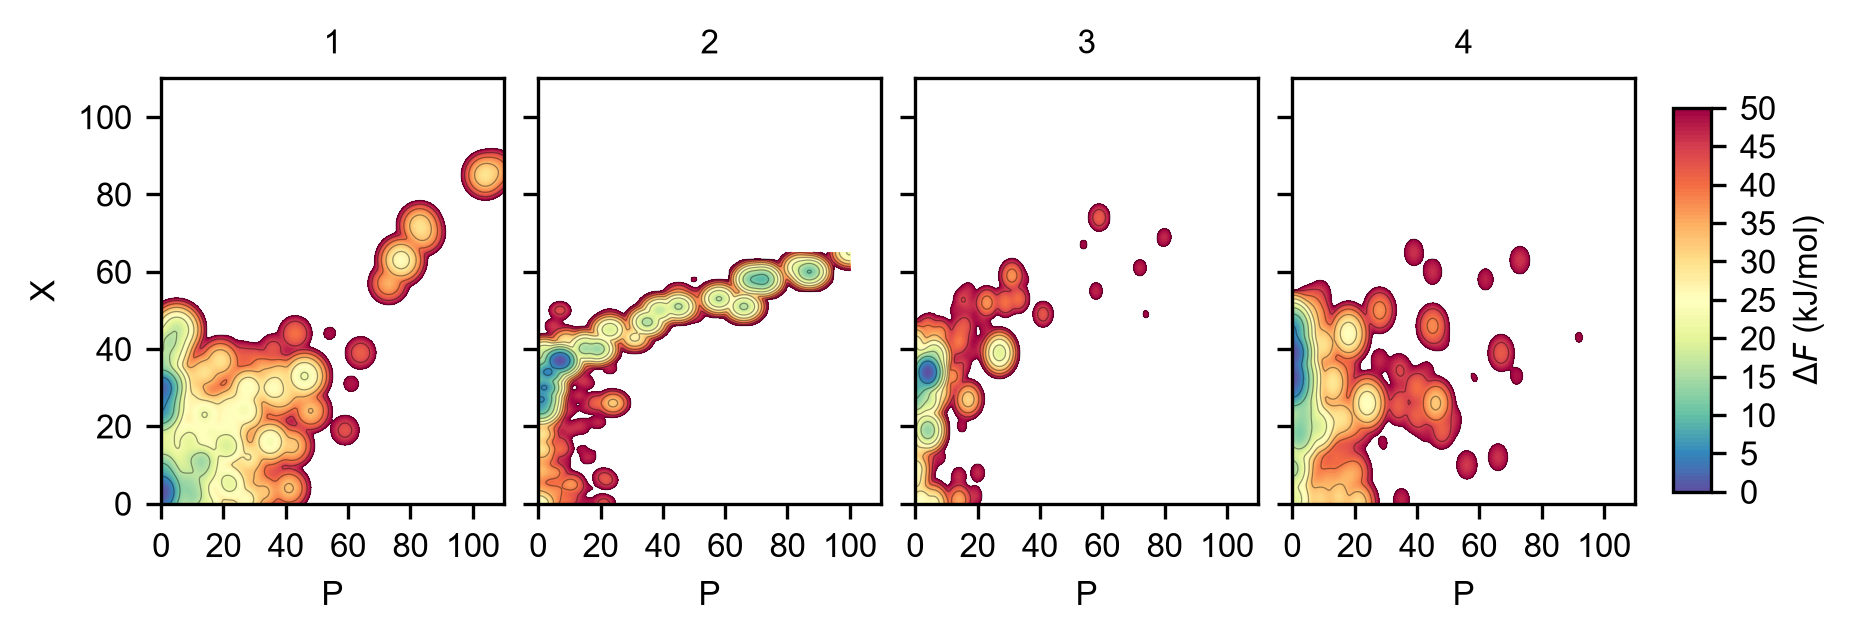

In [43]:
# --------------------------------------------------------------
# Data preparation
# --------------------------------------------------------------

df = colvar.copy()

# Optional: remove t = 0
df = df[df["time"] > 0]

Fmax = 50

var1 = "P"
var2 = "X"

T = 300
BETA = 1 / (KB * T)


# --------------------------------------------------------------
# Figure setup
# --------------------------------------------------------------

fig, axes = plt.subplots(
    1, 4,
    figsize=(16 * cm2inch, 5 * cm2inch),
    dpi=300,
    sharex=True,
    sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.86,
    bottom=0.18,
    top=0.90,
    wspace=0.1
)

pp = None


# --------------------------------------------------------------
# Calculate and plot FES
# --------------------------------------------------------------

for i, ax in enumerate(axes):

    # Select repeat
    data = df[df["Repeat"] == i + 1].copy()

    # ----------------------------------------------------------
    # CVs
    # ----------------------------------------------------------

    cv1 = data[var1].to_numpy(dtype=float)
    cv2 = data[var2].to_numpy(dtype=float)

    cv = np.vstack([cv1, cv2])

    # ----------------------------------------------------------
    # Weights from OPES bias
    # ----------------------------------------------------------

    bias = data["opes1.bias"].to_numpy(dtype=float)
    logweights = BETA * (bias - np.max(bias))
    w = np.exp(logweights)
    # Normalize weights
    w /= np.sum(w)

    # ----------------------------------------------------------
    # Compute FES
    # ----------------------------------------------------------

    fes, grid, bounds, error = compute_fes(
        cv.T,
        weights=w,
        blocks=1,
        kbt=KB * T,
        bandwidth=0.015,
        scale_by="range",
        plot=False,
        plot_max_fes=100,
        eps=1e-10,
        backend="KDEpy",
    )

    # Bounds -> extent for matplotlib
    extent = [
        item
        for sublist in bounds
        for item in sublist
    ]

    # ----------------------------------------------------------
    # Filled contour
    # ----------------------------------------------------------

    pp = ax.contourf(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax, 101),
        cmap="Spectral_r"
    )

    # ----------------------------------------------------------
    # Contour lines
    # ----------------------------------------------------------

    ax.contour(
        fes,
        extent=extent,
        levels=np.linspace(0, Fmax, 10),
        colors="black",
        linewidths=0.3,
        alpha=0.4
    )

    # ----------------------------------------------------------
    # Panel title
    # ----------------------------------------------------------

    ax.set_title(f"{i + 1}")

    # ----------------------------------------------------------
    # Axis labels
    # ----------------------------------------------------------

    ax.set_xlabel(var1)

    if i == 0:
        ax.set_ylabel(var2)

    # Tick parameters
    ax.tick_params(
        direction="out",
        top=False,
        right=False,
    )


# --------------------------------------------------------------
# Axis limits
# --------------------------------------------------------------

for ax in axes:

    ax.set_xlim(0, 110)
    ax.set_ylim(0, 110)

    ax.set_xticks(np.arange(0, 111, 20), )
    ax.set_yticks(np.arange(0, 111, 20))


# --------------------------------------------------------------
# Shared colorbar
# --------------------------------------------------------------

cbar_ax = fig.add_axes(
    [0.88, 0.20, 0.02, 0.65]
)

cbar = fig.colorbar(
    pp,
    cax=cbar_ax
)

cbar.set_ticks(
    np.arange(0, Fmax + 1, 5)
)

cbar.set_label(
    r"$\Delta F$ (kJ/mol)"
)


# --------------------------------------------------------------
# Save figure
# --------------------------------------------------------------

plt.savefig(
    f"images/FB_FES_{var1}_{var2}_weighted_all.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()